# Data transformation, visualization, and feature selection

A practical companion to **Scikit-learn Essentials Tutorial**.

**Your task:** inspect two imperfect tables of hourly energy data, explain useful
patterns with a few clear figures, and forecast gas generation one hour ahead.
All data are synthetic and generated below. No downloads, CSV files, API keys, or
extra plotting packages are needed.

The central workflow is:

**Question → clean table → informative plot → feature hypothesis → chronological comparison.**

Every section explains the question, the Python operation, and what the result can
justify. The emphasis is on doing a small number of things well under time pressure.
This is a practice example, not a description of any employer's assessment.

### Suggested route

| Route | Sections | Suggested study time |
|---|---|---:|
| Clean and reshape data | 0–5 | 25–35 minutes |
| Find and present patterns | 6–9 | 30–40 minutes |
| Build and compare feature sets | 10–15 | 40–55 minutes |
| Optional selector and category examples | 16–18 | 20–30 minutes |
| Reference and exercises | 19–20 | As needed |

These are estimates for reading and running the cells; recreating the operations
from memory will take longer. Run the core in order. Sections 16–18 are independent
of the core result and can be skipped.

**Keep three questions separate:** Does a feature have an interesting association?
Does it improve future predictions beyond the existing features? Is its effect
causal? This notebook addresses the first two; the figures do not establish causality.

## 0. Setup and a small plotting vocabulary

Select the Python environment you used for the earlier notebook. It needs
`numpy`, `pandas`, `matplotlib`, and `scikit-learn`, plus a working notebook kernel.
Use **Restart Kernel → Run All** when checking that your notebook is reproducible.

We use one plotting pattern throughout:

```python
fig, ax = plt.subplots(figsize=(8, 4))
some_series.plot(ax=ax)
ax.set(title="The question this plot answers", xlabel="Units", ylabel="Units")
plt.show()
```

`fig` is the complete figure; `ax` is one plotting area. For a new figure, call
`plt.subplots()` again. Passing `ax=ax` to pandas lets you use its short plotting
syntax while keeping control of labels and layout.

[Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 10,
})

## 1. Make the raw tables

Run the generator cell without spending time understanding its simulation code.
The analysis begins in section 2.

- `observations` has one intended row per **timestamp and generation source**.
- `forecasts` has one intended row per **target timestamp**.
- Generation is measured in **MW**; temperature in **°C**; wind speed in **m/s**;
  cloud cover is a fraction between 0 and 1.

### Define the prediction time before choosing features

A timestamp `t` labels the **hour ending at t**. Immediately after the previous
hour ends, we forecast generation for hour `t`. We assume the previous hour's
generation is reported immediately.

| Column or information | Available when predicting hour t? |
|---|---|
| Calendar for hour t | Yes |
| `temp_fcst`, `wind_fcst`, `cloud_fcst` for hour t | Yes: forecasts issued at t − 1 hour |
| Generation through hour t − 1 | Yes under the reporting assumption above |
| Generation during hour t | No: this includes the target and other sources' realized generation |
| `realized_net_load` for hour t | No: a deliberately misleading post-hour measurement |

The task is a sequence of **one-hour-ahead forecasts**. Earlier validation/test
outcomes become available before later predictions. We do not forecast the whole
validation/test block from one fixed starting time.

In [2]:
def make_toy_data(seed=42, days=120):
    """Return raw (observations, forecasts) DataFrames; no files are needed.

    Each timestamp t labels the hour whose average generation is predicted.
    temp_fcst, wind_fcst, cloud_fcst, temp_copy, noise_1, noise_2, and
    constant_sensor are available at t-1 for hour t. Generation is observed
    only after hour t. The deliberately mixed-in realized_net_load column is
    ALSO available only after t: it is leakage bait, not an eligible input.

    Default anomalies: 3 entire observation timestamps absent; 6 exact rows
    duplicated; 12 source labels with case/whitespace issues; one 'bad_reading'
    generation value per source; 29 missing readings in each of four forecast
    sensor columns. Rows are shuffled. Exact counts are also in .attrs.
    """
    if days < 4:
        raise ValueError('Use at least four days so the small anomaly set fits.')
    rng = np.random.default_rng(seed)
    n = 24 * days
    index = pd.date_range('2024-01-01', periods=n, freq='h', tz='UTC')
    hour = np.asarray(index.hour)
    day = np.arange(n) / 24.0
    weekend = np.asarray(index.dayofweek >= 5, dtype=float)

    # State innovations at t are unknown when the t-1 forecast is issued.
    temp_state, wind_state = np.zeros(n), np.zeros(n)
    cloud_state, residual = np.zeros(n), np.zeros(n)
    for t in range(1, n):
        temp_state[t] = 0.95 * temp_state[t-1] + rng.normal(0, 0.6)
        wind_state[t] = 0.90 * wind_state[t-1] + rng.normal(0, 0.5)
        cloud_state[t] = 0.85 * cloud_state[t-1] + rng.normal(0, 0.08)
        residual[t] = 0.75 * residual[t-1] + rng.normal(0, 6)
    past_temp = np.r_[0.0, temp_state[:-1]]
    past_wind = np.r_[0.0, wind_state[:-1]]
    past_cloud = np.r_[0.0, cloud_state[:-1]]
    temp_mean = 15 + 7*np.sin(2*np.pi*(hour-8)/24) + 4*np.sin(2*np.pi*day/45)
    wind_mean = 6 + 1.2*np.sin(2*np.pi*day/10)
    cloud_mean = 0.5 + 0.15*np.sin(2*np.pi*day/6)
    temp_actual = temp_mean + temp_state
    wind_actual = np.maximum(0.1, wind_mean + wind_state)
    cloud_actual = np.clip(cloud_mean + cloud_state, 0.05, 0.95)
    temp_fcst = temp_mean + 0.95*past_temp + rng.normal(0, 0.25, n)
    wind_fcst = np.maximum(0.1, wind_mean + 0.90*past_wind + rng.normal(0, 0.15, n))
    cloud_fcst = np.clip(cloud_mean + 0.85*past_cloud + rng.normal(0, 0.03, n), 0.05, 0.95)

    daylight = np.maximum(0, np.sin(np.pi*(hour-6)/12))
    wind = np.maximum(0, 70 + 18*wind_actual + rng.normal(0, 5, n))
    solar = np.maximum(0, 300*daylight*(1-0.75*cloud_actual) + rng.normal(0, 3, n))
    gas = (400 + 30*np.cos(2*np.pi*hour/24) - 20*weekend
           + 1.6*(temp_actual-15)**2 - 9*wind_actual - 0.20*solar
           + residual + rng.normal(0, 8, n))
    timestamps = index.strftime('%Y-%m-%dT%H:%M:%SZ')
    observations = pd.DataFrame({'timestamp':timestamps, 'gas':gas, 'wind':wind, 'solar':solar})
    observations = observations.melt(id_vars='timestamp', var_name='source', value_name='generation_mw')
    forecasts = pd.DataFrame({
        'timestamp':timestamps, 'temp_fcst':temp_fcst, 'wind_fcst':wind_fcst,
        'cloud_fcst':cloud_fcst, 'temp_copy':temp_fcst + rng.normal(0, 0.05, n),
        'noise_1':rng.normal(size=n), 'noise_2':rng.normal(size=n),
        'constant_sensor':7.0, 'realized_net_load':gas + rng.normal(0, 1, n)})

    # Three complete observation hours disappear; forecasts retain the full grid.
    missing_times = timestamps[[n//4, n//2, 3*n//4]].tolist()
    observations = observations.loc[~observations['timestamp'].isin(missing_times)].reset_index(drop=True)
    messy = rng.choice(observations.index, size=12, replace=False)
    for i, row in enumerate(messy):
        name = observations.at[row, 'source']
        observations.at[row, 'source'] = ' '+name.upper()+' ' if i < 6 else name.title()+'  '
    observations['generation_mw'] = observations['generation_mw'].astype(object)
    malformed = []
    for source in ['gas', 'wind', 'solar']:
        eligible = observations.index[observations['source'].eq(source)]
        row = int(rng.choice(eligible))
        observations.at[row, 'generation_mw'] = 'bad_reading'
        malformed.append(row)
    clean_rows = observations.index.difference(list(messy) + malformed)
    duplicates = rng.choice(clean_rows, size=6, replace=False)
    observations = pd.concat([observations, observations.loc[duplicates]], ignore_index=True)
    missing_sensor_count = max(1, int(round(0.01*n)))
    for column in ['temp_fcst', 'wind_fcst', 'cloud_fcst', 'temp_copy']:
        rows = rng.choice(forecasts.index, size=missing_sensor_count, replace=False)
        forecasts.loc[rows, column] = np.nan
    observations = observations.sample(frac=1, random_state=seed).reset_index(drop=True)
    forecasts = forecasts.sample(frac=1, random_state=seed+1).reset_index(drop=True)
    anomalies = {'missing_observation_timestamps':missing_times, 'exact_duplicate_rows':6,
                 'messy_source_labels':12, 'malformed_generation_values_per_source':1,
                 'missing_values_per_forecast_sensor':missing_sensor_count,
                 'forecast_sensor_columns':['temp_fcst','wind_fcst','cloud_fcst','temp_copy']}
    observations.attrs['anomalies'] = anomalies.copy()
    forecasts.attrs['anomalies'] = anomalies.copy()
    return observations, forecasts


observations, forecasts = make_toy_data()
print("Observations:", observations.shape, "| Forecasts:", forecasts.shape)
display(observations.head())
display(forecasts.head())

Observations: (8637, 3) | Forecasts: (2880, 9)


,timestamp,source,generation_mw
0,2024-02-24T18:00:00Z,gas,437.136
1,2024-03-29T03:00:00Z,solar,1.173
2,2024-03-12T16:00:00Z,wind,190.100
3,2024-02-13T15:00:00Z,gas,401.918
4,2024-01-12T01:00:00Z,wind,221.280


,timestamp,temp_fcst,wind_fcst,cloud_fcst,temp_copy,noise_1,noise_2,constant_sensor,realized_net_load
0,2024-03-17T03:00:00Z,4.027,5.345,0.436,4.031,0.480,1.226,7.000,535.394
1,2024-03-02T05:00:00Z,14.794,7.103,0.732,14.807,0.367,1.870,7.000,365.040
2,2024-04-04T18:00:00Z,17.907,6.043,0.232,17.882,0.056,0.078,7.000,362.581
3,2024-04-15T18:00:00Z,21.036,4.382,0.435,21.020,-1.001,-0.146,7.000,438.150
4,2024-02-09T12:00:00Z,20.463,5.571,0.368,20.453,-0.627,-1.155,7.000,354.155


## 2. Inspect and clean before plotting

**Question:** what does one row represent, and are the types and keys trustworthy?

`info()` checks types and nonmissing counts. `isna().mean()` gives missing fractions.
`value_counts()` exposes inconsistent labels. A numeric-looking column with dtype
`object` may contain a string such as `"bad_reading"`.

Keep the raw frames unchanged. Cleaning rules below are fixed structural rules,
so applying them before the split does not learn a relationship from future targets.
Data-dependent choices, such as imputation values or outlier cutoffs, come later.

In [3]:
observations.info()
display(observations["source"].value_counts(dropna=False))
display(forecasts.isna().mean().sort_values(ascending=False).rename("missing_fraction"))
print("Exact duplicated observation rows:", observations.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8637 entries, 0 to 8636
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   timestamp      8637 non-null   object
 1   source         8637 non-null   object
 2   generation_mw  8637 non-null   object
dtypes: object(3)
memory usage: 202.6+ KB


source
solar      2876
wind       2876
gas        2873
 GAS          3
Wind          3
 SOLAR        2
Gas           2
 WIND         1
Solar         1
Name: count, dtype: int64

temp_fcst           0.010
cloud_fcst          0.010
wind_fcst           0.010
temp_copy           0.010
timestamp           0.000
noise_1             0.000
noise_2             0.000
constant_sensor     0.000
realized_net_load   0.000
Name: missing_fraction, dtype: float64

Exact duplicated observation rows: 6


### Parse types, standardize labels, and inspect duplicate keys

`errors="coerce"` turns invalid values into `NaT` (dates) or `NaN` (numbers).
Count those failures rather than silently forgetting them. We keep missing
generation values missing: they are not zero generation.

Identical duplicate records can be removed here. Conflicting rows with the same
key need investigation: perhaps a site/source identifier is missing, or one record
is a revision. We explicitly stop if that ambiguity remains.

In [4]:
obs = observations.copy()
weather = forecasts.copy()

obs["timestamp"] = pd.to_datetime(obs["timestamp"], errors="coerce", utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], errors="coerce", utc=True)
obs["source"] = obs["source"].astype("string").str.strip().str.lower()
obs["generation_mw"] = pd.to_numeric(obs["generation_mw"], errors="coerce")

print("Unparseable timestamps:", obs["timestamp"].isna().sum())
print("Missing or invalid generation readings:", obs["generation_mw"].isna().sum())
display(obs.loc[obs["generation_mw"].isna()])

obs = (
    obs.dropna(subset=["timestamp", "source"])
       .drop_duplicates()
       .sort_values(["timestamp", "source"])
       .reset_index(drop=True)
)
weather = weather.dropna(subset=["timestamp"]).sort_values("timestamp")

assert not obs.duplicated(["timestamp", "source"]).any(), "Investigate conflicting keys."
assert not weather["timestamp"].duplicated().any(), "Forecast join would multiply rows."
assert set(obs["source"]) == {"gas", "wind", "solar"}
print("Cleaned observation rows:", len(obs))

Unparseable timestamps: 0
Missing or invalid generation readings: 3


,timestamp,source,generation_mw
2362,2024-04-21 13:00:00+00:00,solar,NaN
5404,2024-02-15 02:00:00+00:00,wind,NaN
7725,2024-01-10 16:00:00+00:00,gas,NaN


Cleaned observation rows: 8631


## 3. Reshape, restore the time grid, and join

### Long versus wide

The original long format is convenient for grouping by source. A wide table
with columns `gas`, `wind`, and `solar` is convenient for plotting simultaneous
series and constructing a forecasting row.

- `pivot` rearranges unique key combinations; it does not average them.
- `pivot_table(..., aggfunc="mean")` deliberately aggregates multiple values.
- `melt` moves columns back into a category/value pair.

A duplicate-key error is a useful diagnostic, not a reason to average records
without understanding them.

[pandas reshaping guide](https://pandas.pydata.org/docs/user_guide/reshaping.html)

In [5]:
wide = (
    obs.pivot(index="timestamp", columns="source", values="generation_mw")
       .sort_index()
       .rename_axis(columns=None)
)
display(wide.head())

long_again = wide.reset_index().melt(
    id_vars="timestamp",
    value_vars=["gas", "wind", "solar"],
    var_name="source",
    value_name="generation_mw",
)
display(long_again.head())

,gas,solar,wind
timestamp,,,
2024-01-01 00:00:00+00:00,433.034,0.000,175.824
2024-01-01 01:00:00+00:00,449.793,1.495,173.553
2024-01-01 02:00:00+00:00,481.022,3.655,144.221
2024-01-01 03:00:00+00:00,464.806,0.000,149.767
2024-01-01 04:00:00+00:00,430.943,1.214,166.582


,timestamp,source,generation_mw
0,2024-01-01 00:00:00+00:00,gas,433.034
1,2024-01-01 01:00:00+00:00,gas,449.793
2,2024-01-01 02:00:00+00:00,gas,481.022
3,2024-01-01 03:00:00+00:00,gas,464.806
4,2024-01-01 04:00:00+00:00,gas,430.943


### Missing rows and a safe join

`asfreq("h")` creates the regular hourly grid and inserts missing hours. This
matters because `shift(24)` means **24 rows**: it means 24 hours only on that grid.
`resample("D").mean()`, in contrast, aggregates observations into daily bins.

Join forecasts by timestamp, using `validate="one_to_one"` to detect accidental
row multiplication. `indicator=True` records whether a matching forecast was found.
We have one forecast per timestamp in this toy table. If forecasts have multiple
issue times or revisions, choose the latest version actually available at each
forecast origin; joining only on target time is insufficient.

[pandas merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)
and [time-series operations](https://pandas.pydata.org/docs/user_guide/timeseries.html)

In [6]:
hourly = wide.asfreq("h")
missing_hours = hourly.index.difference(wide.index)
print("Entire missing observation hours:", list(missing_hours))

data = (
    hourly.reset_index()
          .merge(weather, on="timestamp", how="left",
                 validate="one_to_one", indicator=True)
          .set_index("timestamp")
          .sort_index()
)
display(data["_merge"].value_counts())
data = data.drop(columns="_merge")

assert data.index.is_unique and data.index.is_monotonic_increasing
assert (data.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert len(data) == len(hourly)
print("Regular grid:", data.shape)
display(data.loc[missing_hours, ["gas", "wind", "solar", "temp_fcst"]])

Entire missing observation hours: [Timestamp('2024-01-31 00:00:00+0000', tz='UTC'), Timestamp('2024-03-01 00:00:00+0000', tz='UTC'), Timestamp('2024-03-31 00:00:00+0000', tz='UTC')]


_merge
both          2880
left_only        0
right_only       0
Name: count, dtype: int64

Regular grid: (2880, 11)


,gas,wind,solar,temp_fcst
timestamp,,,,
2024-01-31 00:00:00+00:00,NaN,NaN,NaN,3.781
2024-03-01 00:00:00+00:00,NaN,NaN,NaN,14.090
2024-03-31 00:00:00+00:00,NaN,NaN,NaN,6.921


## 4. Make historical features, then split by time

**Question:** what could we calculate at the actual prediction time?

At target row `t`, `gas_lag_1` is the previous hour's observed gas generation.
The rolling mean uses `shift(1)` **before** `rolling(24)`, so it excludes `gas[t]`.
The change feature is `gas[t−1] − gas[t−2]`, which is also already observed.

These transformations are fixed and use past data only, so we can construct them
across split boundaries. Learning an imputation median from the whole series
would be different: that must happen within each training fit.

For multiple sites or assets, sort and regularize each entity separately and use
grouped lags; a plain `shift` must never cross an entity boundary.

In [7]:
data["target"] = data["gas"]
data["gas_lag_1"] = data["gas"].shift(1)
data["gas_lag_24"] = data["gas"].shift(24)
data["gas_roll_24"] = data["gas"].shift(1).rolling(24, min_periods=24).mean()
data["gas_change_1"] = data["gas"].shift(1) - data["gas"].shift(2)
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)

display(data[["target", "gas_lag_1", "gas_lag_24", "gas_roll_24"]].iloc[22:28])

,target,gas_lag_1,gas_lag_24,gas_roll_24
timestamp,,,,
2024-01-01 22:00:00+00:00,400.565,357.696,NaN,NaN
2024-01-01 23:00:00+00:00,412.789,400.565,NaN,NaN
2024-01-02 00:00:00+00:00,441.064,412.789,433.034,378.934
2024-01-02 01:00:00+00:00,475.533,441.064,449.793,379.269
2024-01-02 02:00:00+00:00,475.074,475.533,481.022,380.341
2024-01-02 03:00:00+00:00,464.016,475.074,464.806,380.094


We reserve the final 20% of clock time for one final assessment and the preceding
20% for validation. All pattern-finding below initially uses **training data only**.

Use one common evaluation population: skip the first 24 hours, missing target
labels, and cases with no previous-hour value for the persistence baseline.
Other predictor gaps are imputed inside each model's pipeline. Do not give each
feature set its own `dropna()`; that would change which hours it is judged on.

This choice evaluates hours where the previous-hour observation exists. In a real
application that must forecast during outages too, add a fallback baseline and
evaluate those hours separately. Never impute a target merely to obtain a score.

[scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html)

In [8]:
train_end = data.index[int(0.60 * len(data))]
valid_end = data.index[int(0.80 * len(data))]
warmup_end = data.index[0] + pd.Timedelta(hours=24)

eligible = (
    (data.index >= warmup_end)
    & data["target"].notna()
    & data["gas_lag_1"].notna()
)
model_data = data.loc[eligible].copy()
train = model_data.loc[model_data.index < train_end].copy()
valid = model_data.loc[
    (model_data.index >= train_end) & (model_data.index < valid_end)
].copy()
test = model_data.loc[model_data.index >= valid_end].copy()

split_summary = pd.DataFrame([
    {"split": name, "rows": len(frame), "first": frame.index.min(), "last": frame.index.max()}
    for name, frame in [("train", train), ("validation", valid), ("test", test)]
]).set_index("split")
display(split_summary)
print("Excluded rows after warmup:",
      int(((data.index >= warmup_end) & ~eligible).sum()))

assert train.index.max() < valid.index.min() < test.index.min()
assert train["target"].notna().all()

,rows,first,last
split,,,
train,1698,2024-01-02 00:00:00+00:00,2024-03-12 23:00:00+00:00
validation,574,2024-03-13 00:00:00+00:00,2024-04-05 23:00:00+00:00
test,576,2024-04-06 00:00:00+00:00,2024-04-29 23:00:00+00:00


Excluded rows after warmup: 8


## 5. Common transformations: summarize, align, and resample

### `agg` reduces groups; `transform` returns one value per original row

`groupby(...).agg(...)` makes a summary table. In a named aggregation such as
`mean_mw=("generation_mw", "mean")`, the new column is `mean_mw`, the input column
is `generation_mw`, and the calculation is a mean.

`transform("mean")` repeats a group mean along the original rows, so pandas can
align it with the original values. Below it is only a **descriptive** within-source
deviation. A group mean calculated using future targets is not a forecasting feature.

[pandas groupby guide](https://pandas.pydata.org/docs/user_guide/groupby.html)

In [9]:
obs_train = obs.loc[obs["timestamp"] < train_end].copy()

source_summary = (
    obs_train.groupby("source", observed=True)
    .agg(
        mean_mw=("generation_mw", "mean"),
        median_mw=("generation_mw", "median"),
        valid_readings=("generation_mw", "count"),
        rows=("generation_mw", "size"),
    )
    .sort_values("mean_mw", ascending=False)
)
display(source_summary)

obs_train["source_mean"] = (
    obs_train.groupby("source", observed=True)["generation_mw"].transform("mean")
)
obs_train["deviation_from_source_mean"] = (
    obs_train["generation_mw"] - obs_train["source_mean"]
)
display(obs_train.head())

,mean_mw,median_mw,valid_readings,rows
source,,,,
gas,382.646,375.113,1725,1726
wind,178.097,179.744,1725,1726
solar,60.338,4.335,1726,1726


,timestamp,source,generation_mw,source_mean,deviation_from_source_mean
0,2024-01-01 00:00:00+00:00,gas,433.034,382.646,50.389
1,2024-01-01 00:00:00+00:00,solar,0.000,60.338,-60.338
2,2024-01-01 00:00:00+00:00,wind,175.824,178.097,-2.273
3,2024-01-01 01:00:00+00:00,gas,449.793,382.646,67.147
4,2024-01-01 01:00:00+00:00,solar,1.495,60.338,-58.843


### Daily summaries with coverage counts

Hourly average power in MW and daily energy in MWh have different meanings.
For complete one-hour intervals, summing hourly MW values and multiplying by
one hour gives MWh. An incomplete day's observed sum is only a partial total.

The table deliberately reports both the daily average and the number of valid
hours. `min_count=24` makes the full-day energy missing unless all 24 hours exist.
UTC avoids daylight-saving day lengths in this toy example. Actual local-time
energy calculations must account for interval durations.

A whole-day aggregate is known after the day ends, even if pandas labels it at
the start of the day. These daily summaries are for retrospective plots.
Because timestamps label hour ends, we use right-closed daily bins: an interval
ending at midnight belongs to the preceding calendar day.

In [10]:
train_hours = data.loc[data.index < train_end].copy()
daily = train_hours["gas"].resample("D", closed="right", label="left").agg(["mean", "count"])
daily = daily.rename(columns={"mean": "mean_mw", "count": "valid_hours"})
daily["energy_mwh_complete_day"] = (
    train_hours["gas"].resample("D", closed="right", label="left").sum(min_count=24) * 1.0
)
display(daily.head())
display(daily.loc[daily["valid_hours"] < 24])

,mean_mw,valid_hours,energy_mwh_complete_day
timestamp,,,
2023-12-31 00:00:00+00:00,433.034,1,NaN
2024-01-01 00:00:00+00:00,379.269,24,"9,102.455"
2024-01-02 00:00:00+00:00,376.635,24,"9,039.234"
2024-01-03 00:00:00+00:00,357.905,24,"8,589.718"
2024-01-04 00:00:00+00:00,405.407,24,"9,729.776"


,mean_mw,valid_hours,energy_mwh_complete_day
timestamp,,,
2023-12-31 00:00:00+00:00,433.034,1,NaN
2024-01-10 00:00:00+00:00,368.617,23,NaN
2024-01-30 00:00:00+00:00,389.383,23,NaN
2024-02-29 00:00:00+00:00,378.042,23,NaN
2024-03-12 00:00:00+00:00,379.046,23,NaN


## 6. Start with time and distributions

**Question 1:** do the series show cycles, gaps, extreme episodes, or drift?

Plot a short window to see within-day detail, then a longer aggregate to see
slower changes. Three months of hourly lines squeezed into one panel can hide
the pattern you care about. A missing observation should appear as a gap.

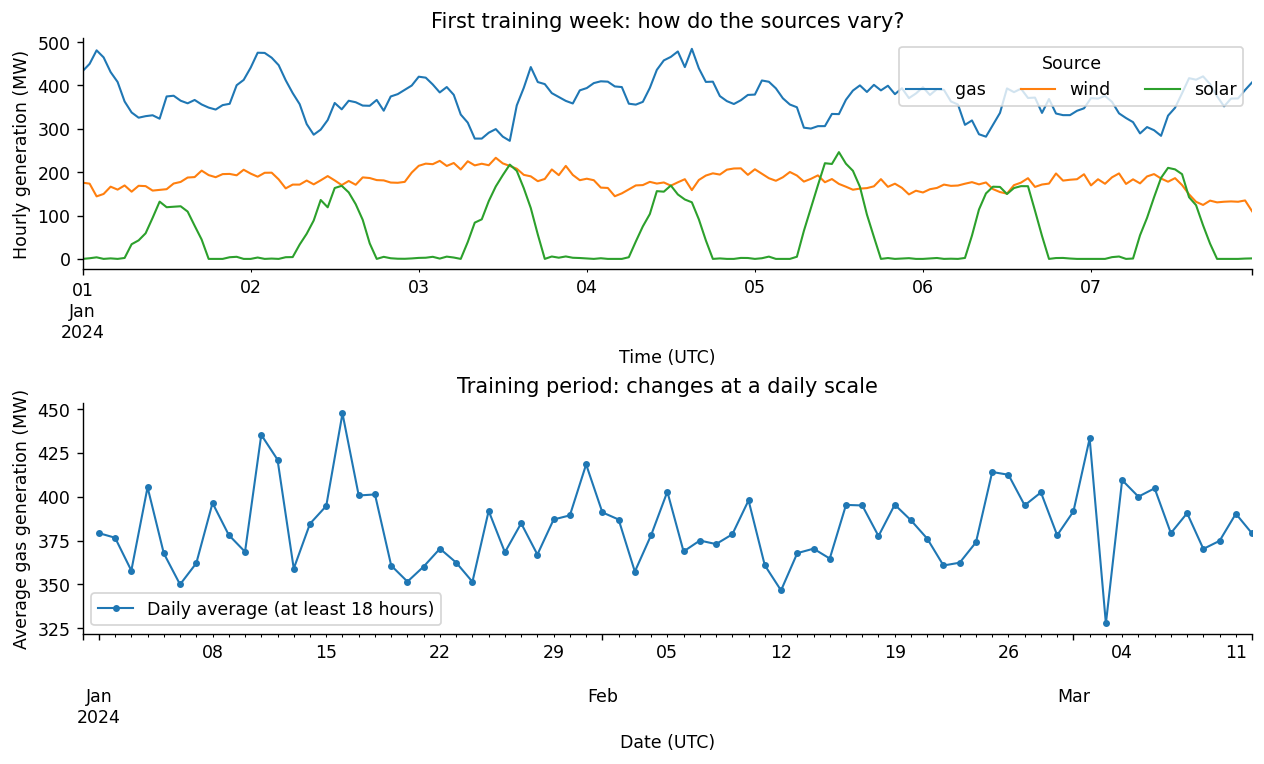

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
week = train_hours.iloc[:24 * 7]
week[["gas", "wind", "solar"]].plot(ax=axes[0], linewidth=1.2)
axes[0].set(title="First training week: how do the sources vary?",
            xlabel="Time (UTC)", ylabel="Hourly generation (MW)")
axes[0].legend(title="Source", ncol=3)

daily["mean_mw"].where(daily["valid_hours"] >= 18).plot(
    ax=axes[1], marker=".", linewidth=1.2, label="Daily average (at least 18 hours)"
)
axes[1].set(title="Training period: changes at a daily scale",
            xlabel="Date (UTC)", ylabel="Average gas generation (MW)")
axes[1].legend()
plt.show()

**Question 2:** how spread out are observations, and do groups have different
distributions?

Use the **same bin edges** for overlaid histograms. `density=True` compares
distribution shapes when group sample sizes differ; `alpha` makes overlap visible.
`label` attaches the legend text when the histogram is drawn.

The box plot summarizes medians and spread. Its outside points are not automatically
data errors: a genuine cold period can produce unusually high generation.

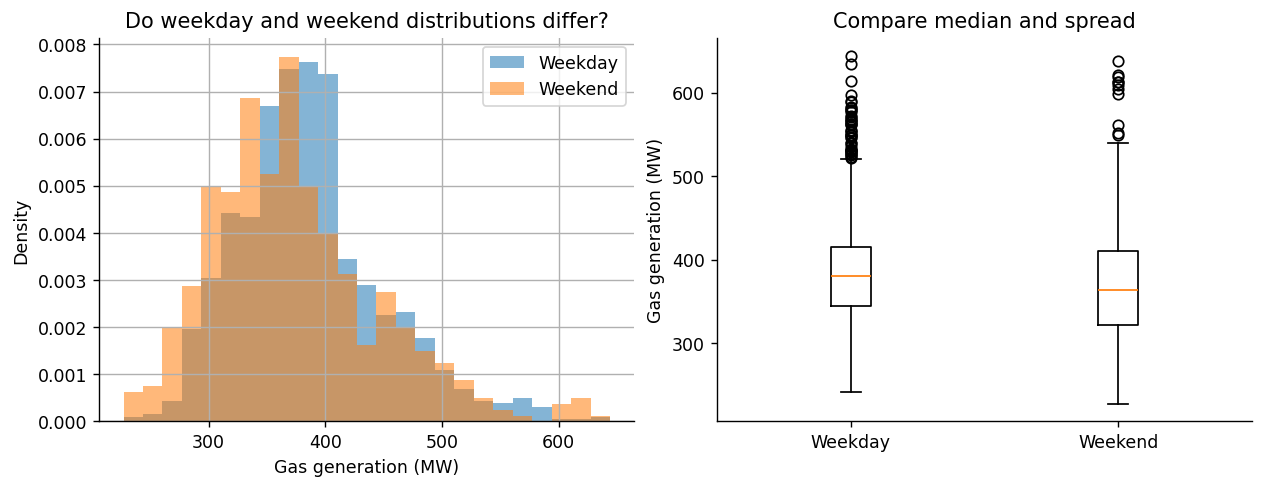

In [12]:
weekday_gas = train.loc[train["is_weekend"] == 0, "target"]
weekend_gas = train.loc[train["is_weekend"] == 1, "target"]
bins = np.histogram_bin_edges(train["target"], bins=25)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
weekday_gas.hist(ax=axes[0], bins=bins, density=True, alpha=0.55, label="Weekday")
weekend_gas.hist(ax=axes[0], bins=bins, density=True, alpha=0.55, label="Weekend")
axes[0].set(title="Do weekday and weekend distributions differ?",
            xlabel="Gas generation (MW)", ylabel="Density")
axes[0].legend()

axes[1].boxplot([weekday_gas.to_numpy(), weekend_gas.to_numpy()], showfliers=True)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Weekday", "Weekend"])
axes[1].set(title="Compare median and spread", ylabel="Gas generation (MW)")
plt.show()

## 7. Reveal calendar patterns with grouping and a heatmap

**Question:** does the daily pattern change on weekends?

Aggregate by both hour and weekend status. A mean curve can suggest a calendar
feature or an interaction. It does not isolate the effect of the calendar:
temperature and other conditions can differ across those same groups.

The heatmap gives a compact view of a two-way table. Keep the axes ordered
meaningfully, include a colorbar with units, and also examine group counts.

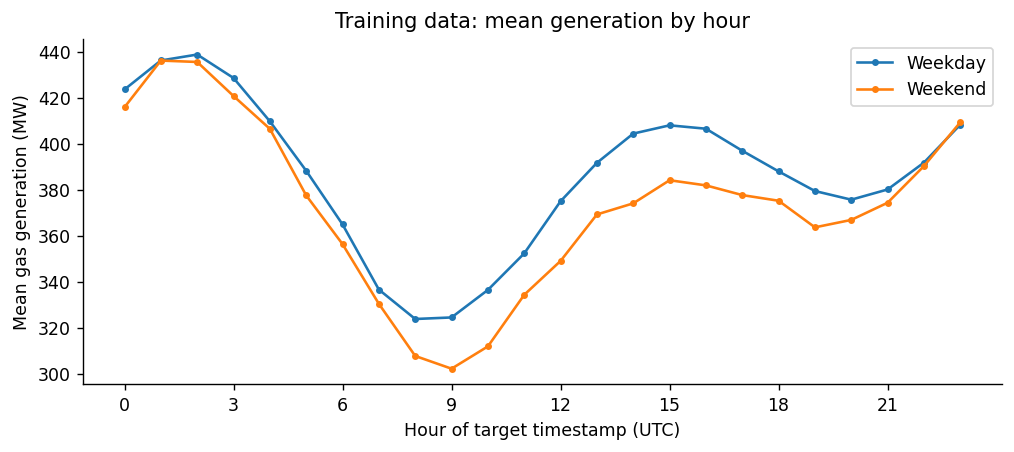

In [13]:
hour_profile = train.pivot_table(
    index="hour", columns="is_weekend", values="target",
    aggfunc="mean", observed=True,
).rename(columns={0: "Weekday", 1: "Weekend"})

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
hour_profile.plot(ax=ax, marker="o", markersize=3)
ax.set(title="Training data: mean generation by hour",
       xlabel="Hour of target timestamp (UTC)", ylabel="Mean gas generation (MW)")
ax.set_xticks(range(0, 24, 3))
ax.legend(title="")
plt.show()

Smallest weekday/hour cell count: 9


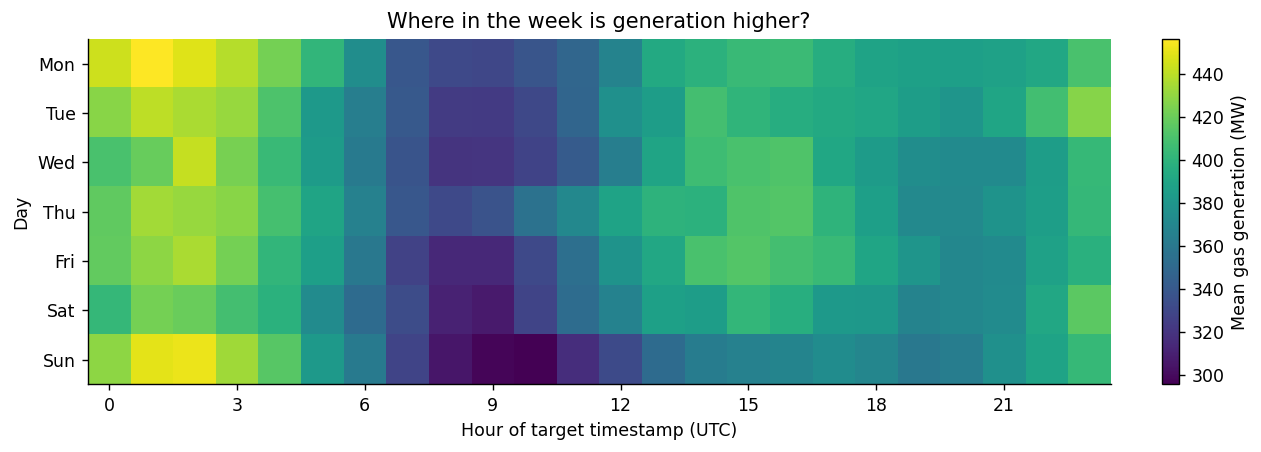

In [14]:
calendar_means = train.pivot_table(
    index="day_of_week", columns="hour", values="target",
    aggfunc="mean", observed=True,
).reindex(index=range(7), columns=range(24))
calendar_counts = train.pivot_table(
    index="day_of_week", columns="hour", values="target",
    aggfunc="count", observed=True,
).reindex(index=range(7), columns=range(24))
print("Smallest weekday/hour cell count:", int(calendar_counts.min().min()))

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
im = ax.imshow(calendar_means.to_numpy(), aspect="auto", cmap="viridis")
ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(range(0, 24, 3))
ax.set(title="Where in the week is generation higher?",
       xlabel="Hour of target timestamp (UTC)", ylabel="Day")
fig.colorbar(im, ax=ax, label="Mean gas generation (MW)")
plt.show()

## 8. Scatterplots and binned means: look beyond correlation

**Question:** is the target's relationship with a candidate feature roughly
linear, curved, or dominated by a few points?

Use small, transparent points to reduce overplotting. Start with a few plausible
features, not every pair of columns. The temperature pattern here is intentionally
curved, while lagged generation is strongly associated with the current target.

A useful feature can have weak marginal correlation. For example, if `X` is
symmetric around zero and `Y = X²`, positive and negative slopes cancel in the
linear correlation even though `X` completely determines `Y`.

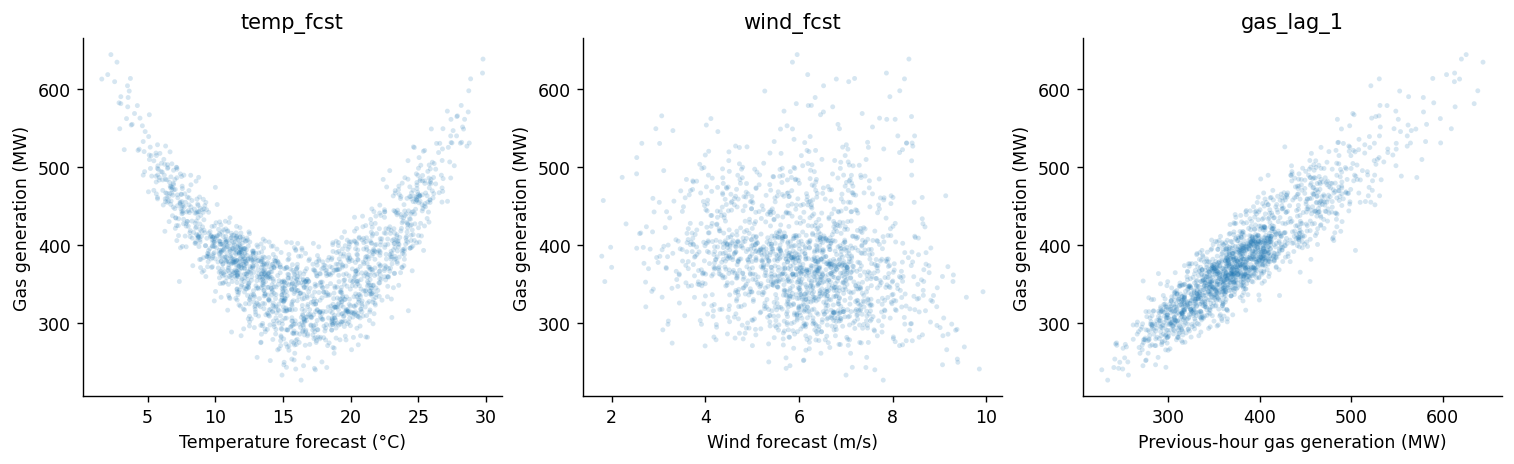

In [15]:
plot_features = ["temp_fcst", "wind_fcst", "gas_lag_1"]
plot_labels = ["Temperature forecast (°C)", "Wind forecast (m/s)",
               "Previous-hour gas generation (MW)"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, column, label in zip(axes, plot_features, plot_labels):
    ax.scatter(train[column], train["target"], s=8, alpha=0.18, edgecolors="none")
    ax.set(xlabel=label, ylabel="Gas generation (MW)", title=column)
plt.show()

### Compress a noisy cloud into an interpretable curve

`qcut` divides the **training** feature into approximately equal-count bins.
Ties can reduce the number of bins when `duplicates="drop"`. In each bin we
compute mean temperature, mean target, and count. `observed=True` keeps only
represented categorical groups.

This is an exploratory summary, not an adjusted response curve. The count panel
shows how much data support each point; it is not a confidence interval.
If bins become model inputs, their boundaries must be learned on each training
fold and reused on that fold's validation data.

[pandas qcut](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html)

,temp_mean,target_mean,n
temp_bin,,,
"(1.6090000000000002, 8.37]",6.322,482.786,169
"(8.37, 10.848]",9.748,403.408,169
"(10.848, 12.281]",11.615,377.346,168
"(12.281, 13.955]",13.135,354.160,169
"(13.955, 15.695]",14.843,332.931,168
"(15.695, 17.536]",16.591,326.066,169
"(17.536, 19.545]",18.623,334.402,168
"(19.545, 21.444]",20.511,351.208,169
"(21.444, 23.828]",22.577,393.190,168


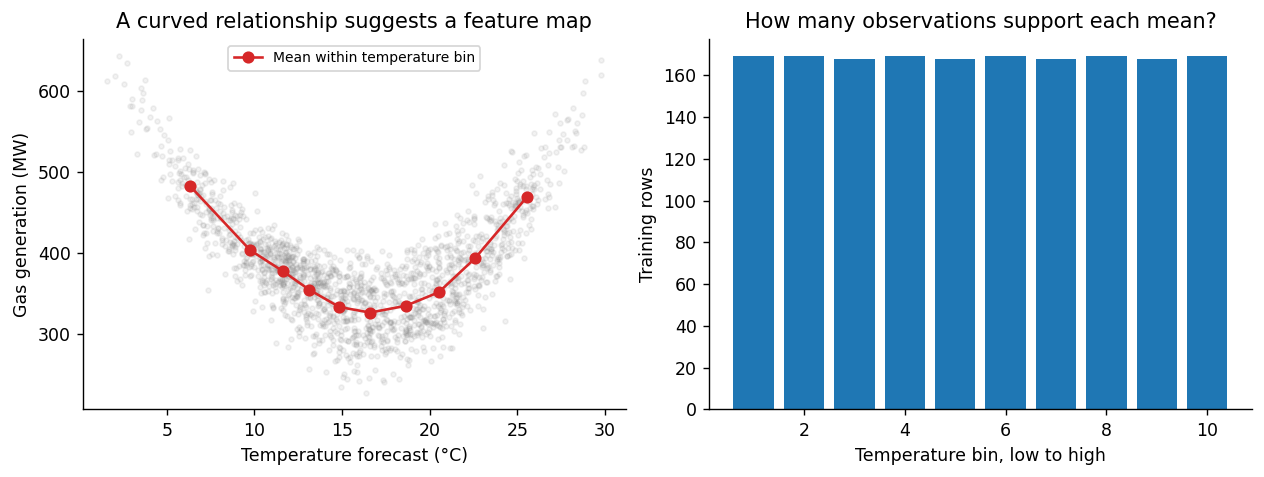

In [16]:
view = train[["temp_fcst", "target"]].dropna().copy()
view["temp_bin"] = pd.qcut(view["temp_fcst"], q=10, duplicates="drop")
curve = (
    view.groupby("temp_bin", observed=True)
    .agg(
        temp_mean=("temp_fcst", "mean"),
        target_mean=("target", "mean"),
        n=("target", "size"),
    )
)
display(curve)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
axes[0].scatter(view["temp_fcst"], view["target"], s=8, alpha=0.10, color="gray")
axes[0].plot(curve["temp_mean"], curve["target_mean"], "o-", color="tab:red",
             label="Mean within temperature bin")
axes[0].set(title="A curved relationship suggests a feature map",
            xlabel="Temperature forecast (°C)", ylabel="Gas generation (MW)")
axes[0].legend(fontsize=8)
axes[1].bar(np.arange(len(curve)) + 1, curve["n"], color="tab:blue")
axes[1].set(title="How many observations support each mean?",
            xlabel="Temperature bin, low to high", ylabel="Training rows")
plt.show()

## 9. Many features: audit first, rank second

Start with **availability and meaning**, then missingness, constants, and redundancy.
Use an explicit predictor list; `data.drop(columns="target")` would accidentally
include the target's original `gas` column and post-hour measurements.

The audit reports training-only missingness and uniqueness. Pearson ranks linear
associations; Spearman ranks monotone associations. Both are marginal screens,
so they can miss nonlinear or conditional value.

A constant column contributes no variation. A nearly duplicated sensor may add
little information, but it can still be useful when the other sensor is missing.
An entity ID can support useful group effects; an arbitrary record ID usually
cannot. Interpret columns before dropping them.

In [17]:
history_cols = ["gas_lag_1", "gas_lag_24", "gas_roll_24", "gas_change_1"]
calendar_cols = ["hour_sin", "hour_cos", "is_weekend"]
weather_cols = ["temp_fcst", "wind_fcst", "cloud_fcst"]
extra_cols = ["temp_copy", "noise_1", "noise_2"]
audit_cols = history_cols + calendar_cols + weather_cols + extra_cols + ["constant_sensor"]

feature_audit = pd.DataFrame({
    "missing_pct": 100 * train[audit_cols].isna().mean(),
    "n_unique": train[audit_cols].nunique(),
})
nonconstant = feature_audit.index[feature_audit["n_unique"] > 1].tolist()
feature_audit["pearson_with_target"] = train[nonconstant].corrwith(train["target"])
feature_audit["spearman_with_target"] = train[nonconstant].corrwith(
    train["target"], method="spearman"
)
display(feature_audit.sort_values("missing_pct", ascending=False))

leaky_correlation = train["realized_net_load"].corr(train["target"])
print(f"Post-hour realized_net_load correlation: {leaky_correlation:.4f}")
print("Exclude it anyway: it is unavailable at the forecast origin.")

,missing_pct,n_unique,pearson_with_target,spearman_with_target
gas_roll_24,4.064,1629,0.192,0.178
wind_fcst,0.942,1682,-0.147,-0.180
temp_copy,0.942,1682,-0.093,-0.119
cloud_fcst,0.766,1679,-0.029,-0.037
temp_fcst,0.707,1686,-0.094,-0.116
gas_lag_24,0.177,1695,0.664,0.683
gas_change_1,0.177,1695,0.343,0.327
hour_cos,0.000,22,0.315,0.354
gas_lag_1,0.000,1698,0.917,0.903
hour_sin,0.000,22,-0.128,-0.167


Post-hour realized_net_load correlation: 0.9999
Exclude it anyway: it is unavailable at the forecast origin.


### A small correlation heatmap answers a specific question

**Question:** which candidate features duplicate one another?

For hundreds of columns, show a manageable subset selected by meaning or a screening
table. A giant heatmap is hard to interpret. Here `temp_copy` illustrates redundancy.
Do not delete every correlated feature automatically: combinations can be useful,
and regularization can stabilize a model that retains them.

The diagonal is one; the color scale is fixed at −1 to 1. Correlations below use
available pairs of observations, so pairwise sample sizes can differ with missingness.

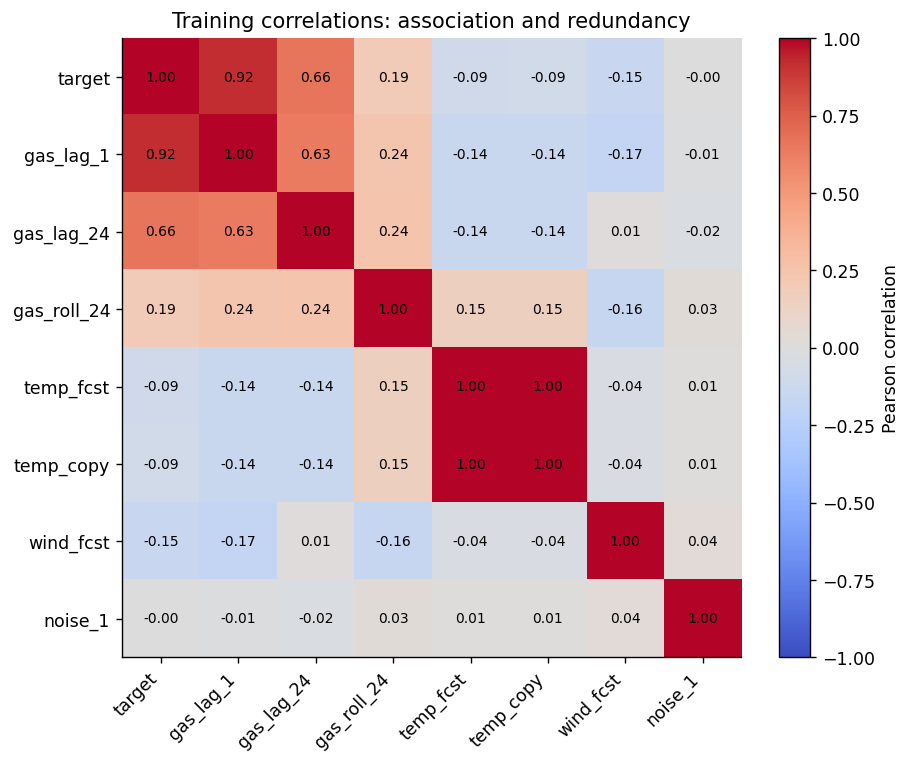

In [18]:
correlation_cols = [
    "target", "gas_lag_1", "gas_lag_24", "gas_roll_24",
    "temp_fcst", "temp_copy", "wind_fcst", "noise_1",
]
corr = train[correlation_cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Training correlations: association and redundancy")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.show()

## 10. Turn a plot into a small, testable feature hypothesis

The temperature curve suggests a quadratic feature. Calendar features represent
periodicity: hours 23 and 0 are close on a clock, even though their integer values
are far apart. A daylight × clear-sky interaction represents the idea that cloud
cover matters differently at night and during the day.

| Pattern or hypothesis | Candidate representation |
|---|---|
| Daily periodicity | `sin(2π hour / 24)` and `cos(2π hour / 24)` |
| High generation at both temperature extremes | `(temperature − 15)²` |
| Cloud effects depend on daylight | `daylight_proxy × (1 − cloud_fraction)` |
| Recent level and persistence | Lagged values and trailing mean |
| Recent movement | Difference between two already-observed values |

Here 15°C and the daylight formula are fixed illustrative choices. We do not
optimize them against the test set. A linear model with a quadratic column remains
linear **in its coefficients**:

$$\widehat y=\beta_0+\beta_1 T+\beta_2(T-15)^2+\cdots.$$

Do not create every polynomial and interaction indiscriminately. Add a few that
answer specific questions, then test their incremental contribution.

In [19]:
def add_feature_maps(frame):
    result = frame.copy()
    result["temp_sq"] = (result["temp_fcst"] - 15.0) ** 2
    daylight = np.maximum(0, np.sin(np.pi * (result["hour"] - 6) / 12))
    result["daylight_clear"] = daylight * (1 - result["cloud_fcst"])
    return result

train = add_feature_maps(train)
valid = add_feature_maps(valid)
test = add_feature_maps(test)

shape_cols = ["temp_sq", "daylight_clear"]
all_feature_cols = history_cols + calendar_cols + weather_cols + shape_cols + extra_cols
forbidden_cols = {"target", "gas", "wind", "solar", "realized_net_load"}
assert not set(all_feature_cols) & forbidden_cols
assert "constant_sensor" not in all_feature_cols

X_train = train[all_feature_cols]
y_train = train["target"]
display(train[["temp_fcst", "temp_sq", "hour", "cloud_fcst", "daylight_clear"]].head())

,temp_fcst,temp_sq,hour,cloud_fcst,daylight_clear
timestamp,,,,,
2024-01-02 00:00:00+00:00,8.607,40.864,0,0.723,0.000
2024-01-02 01:00:00+00:00,7.553,55.454,1,0.551,0.000
2024-01-02 02:00:00+00:00,6.737,68.275,2,0.558,0.000
2024-01-02 03:00:00+00:00,6.867,66.143,3,0.532,0.000
2024-01-02 04:00:00+00:00,7.007,63.881,4,0.534,0.000


## 11. Use baseline residuals to find what is still missing

**Question:** what pattern remains after a simple model uses history and calendar?

Fit a baseline on the earlier part of training, then compute its errors on the
last two training weeks. These are future observations relative to that fit,
but still part of our **development process**.

Define `error = actual − prediction`: positive errors mean underprediction.
If the mean error varies with temperature, the baseline may be missing temperature
information or a suitable feature map. That suggests an experiment; it does not
prove that the extra feature will generalize.

The imputation and scaling below are learned only from the fitting subset.
In regression-course language, checking future residuals asks whether the fitted
conditional mean still leaves predictable structure.

,temperature,mean_error,n
bin,,,
"(4.028, 11.259]",8.764,8.590,42
"(11.259, 12.846]",12.078,2.022,42
"(12.846, 14.577]",13.726,-4.967,41
"(14.577, 17.205]",15.916,-4.199,42
"(17.205, 19.378]",18.414,-5.726,41
"(19.378, 21.658]",20.538,-3.743,42
"(21.658, 24.316]",22.982,2.668,41
"(24.316, 29.785]",25.999,15.431,42


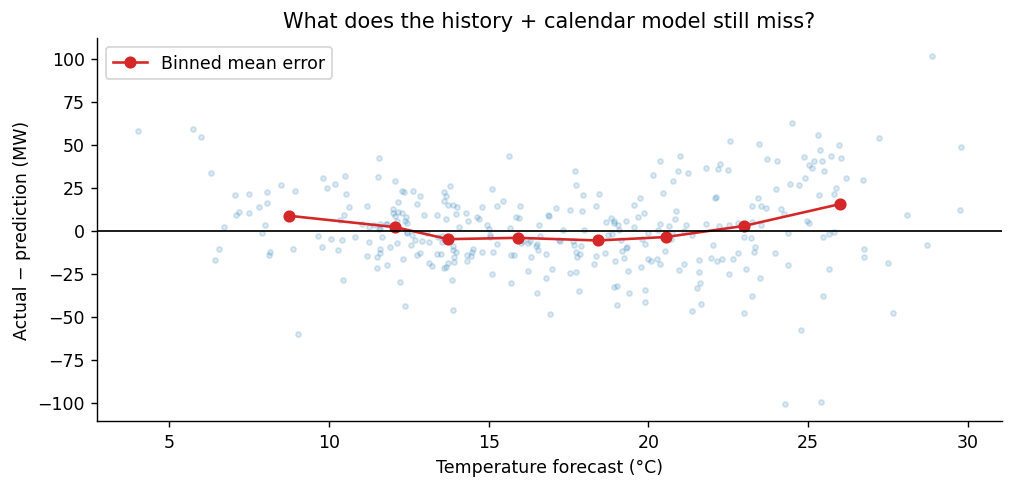

In [20]:
def make_ridge(alpha=10.0):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])

diagnostic_start = train_end - pd.Timedelta(days=14)
early = train.loc[train.index < diagnostic_start]
diagnostic = train.loc[train.index >= diagnostic_start]
baseline_cols = history_cols + calendar_cols
baseline_model = make_ridge().fit(early[baseline_cols], early["target"])

residual_view = diagnostic[["temp_fcst", "target"]].copy()
residual_view["error"] = diagnostic["target"] - baseline_model.predict(
    diagnostic[baseline_cols]
)
residual_view = residual_view.dropna(subset=["temp_fcst"])
residual_view["bin"] = pd.qcut(residual_view["temp_fcst"], q=8, duplicates="drop")
residual_curve = residual_view.groupby("bin", observed=True).agg(
    temperature=("temp_fcst", "mean"),
    mean_error=("error", "mean"),
    n=("error", "size"),
)
display(residual_curve)

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.scatter(residual_view["temp_fcst"], residual_view["error"], s=9, alpha=0.16)
ax.plot(residual_curve["temperature"], residual_curve["mean_error"], "o-",
        color="tab:red", label="Binned mean error")
ax.axhline(0, color="black", linewidth=1)
ax.set(title="What does the history + calendar model still miss?",
       xlabel="Temperature forecast (°C)", ylabel="Actual − prediction (MW)")
ax.legend()
plt.show()

## 12. Select features by comparing the same future windows

Use three expanding training windows, each followed by a **seven-day** validation
window within the training period. We use timestamp boundaries because missing
target exclusions left a few gaps in the eligible rows.

The index pairs below can be passed directly as `cv=...` to scikit-learn.
For a fully observed hourly grid, `TimeSeriesSplit(n_splits=3, test_size=168)`
is a shorter alternative. Its sizes and `gap` count rows; it does not know the
forecast horizon or when labels become available.

Here previous-hour labels are available at the next forecast origin, so we need
no extra embargo. Longer label horizons or delayed reporting require a suitable
gap. It is not automatically equal to the maximum lag.

[TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)

In [21]:
cv_splits = []
fold_rows = []
for fold, days_before_end in enumerate([21, 14, 7], start=1):
    start = train_end - pd.Timedelta(days=days_before_end)
    stop = start + pd.Timedelta(days=7)
    fit_positions = np.flatnonzero(train.index < start)
    holdout_positions = np.flatnonzero((train.index >= start) & (train.index < stop))
    cv_splits.append((fit_positions, holdout_positions))
    assert train.index[fit_positions].max() <= (
        train.index[holdout_positions].min() - pd.Timedelta(hours=1)
    )
    fold_rows.append({
        "fold": fold, "fit_rows": len(fit_positions),
        "evaluation_rows": len(holdout_positions),
        "evaluation_start": start, "evaluation_end_exclusive": stop,
    })
display(pd.DataFrame(fold_rows).set_index("fold"))

,fit_rows,evaluation_rows,evaluation_start,evaluation_end_exclusive
fold,,,,
1,1196,168,2024-02-21 00:00:00+00:00,2024-02-28 00:00:00+00:00
2,1364,166,2024-02-28 00:00:00+00:00,2024-03-06 00:00:00+00:00
3,1530,168,2024-03-06 00:00:00+00:00,2024-03-13 00:00:00+00:00


### Add or remove meaningful groups, then refit

We hold the estimator and Ridge penalty fixed to compare representations quickly.
Every fold learns its own medians, scales, and coefficients. Every candidate is
scored on identical timestamps. Lower RMSE is better; MAE will also be reported
on validation.

RMSE has the target's units and emphasizes large errors:
$$\mathrm{RMSE}=\sqrt{\frac1n\sum_i(y_i-\widehat y_i)^2}.$$

The feature sets test specific hypotheses. The final row removes history from a
rich weather/calendar model; the extra-column row tests whether redundant sensors
and noise help. A noisy column may improve one small sample by chance.

The selection rule is declared now: among sets within **1% of the best mean CV
RMSE**, prefer fewer features, breaking remaining ties by RMSE. This is a practical
simplicity preference, not a significance test.

Our earlier training plots helped suggest these candidates. Inner-CV results are
therefore tuning diagnostics, not a fully untouched estimate of the whole search
process. The outer validation and final test still have separate roles.

In [22]:
core_cols = history_cols + calendar_cols + weather_cols
candidate_sets = {
    "History only": history_cols,
    "+ Calendar": history_cols + calendar_cols,
    "+ Linear weather": core_cols,
    "+ Temperature curve": core_cols + ["temp_sq"],
    "+ Daylight interaction": core_cols + shape_cols,
    "+ Duplicate and noise": all_feature_cols,
    "Weather/calendar, no history": calendar_cols + weather_cols + shape_cols,
}

cv_rows = []
for name, columns in candidate_sets.items():
    fold_rmse = -cross_val_score(
        make_ridge(), train[columns], y_train,
        cv=cv_splits, scoring="neg_root_mean_squared_error", n_jobs=1,
    )
    cv_rows.append({
        "feature_set": name, "n_features": len(columns),
        "mean_rmse": fold_rmse.mean(),
        **{f"fold_{i+1}": value for i, value in enumerate(fold_rmse)},
    })
cv_results = pd.DataFrame(cv_rows).set_index("feature_set")
display(cv_results.sort_values("mean_rmse"))

best_cv_rmse = cv_results["mean_rmse"].min()
shortlist = cv_results.loc[cv_results["mean_rmse"] <= 1.01 * best_cv_rmse]
selected_set = shortlist.sort_values(["n_features", "mean_rmse"]).index[0]
selected_cols = list(candidate_sets[selected_set])
print("Selected feature set:", selected_set)
print("Selected columns:", selected_cols)

persistence_cv = [
    np.sqrt(mean_squared_error(train.iloc[b]["target"], train.iloc[b]["gas_lag_1"]))
    for a, b in cv_splits
]
print("Persistence baseline mean CV RMSE:", round(float(np.mean(persistence_cv)), 3))

,n_features,mean_rmse,fold_1,fold_2,fold_3
feature_set,,,,,
+ Duplicate and noise,15,18.809,19.522,21.361,15.544
+ Daylight interaction,12,18.848,19.839,21.358,15.348
+ Temperature curve,11,18.940,19.745,21.588,15.487
"Weather/calendar, no history",8,20.718,22.979,22.277,16.897
History only,4,23.293,21.754,27.012,21.113
+ Calendar,7,23.573,22.641,27.242,20.837
+ Linear weather,10,23.737,22.951,27.149,21.112


Selected feature set: + Temperature curve
Selected columns: ['gas_lag_1', 'gas_lag_24', 'gas_roll_24', 'gas_change_1', 'hour_sin', 'hour_cos', 'is_weekend', 'temp_fcst', 'wind_fcst', 'cloud_fcst', 'temp_sq']
Persistence baseline mean CV RMSE: 25.988


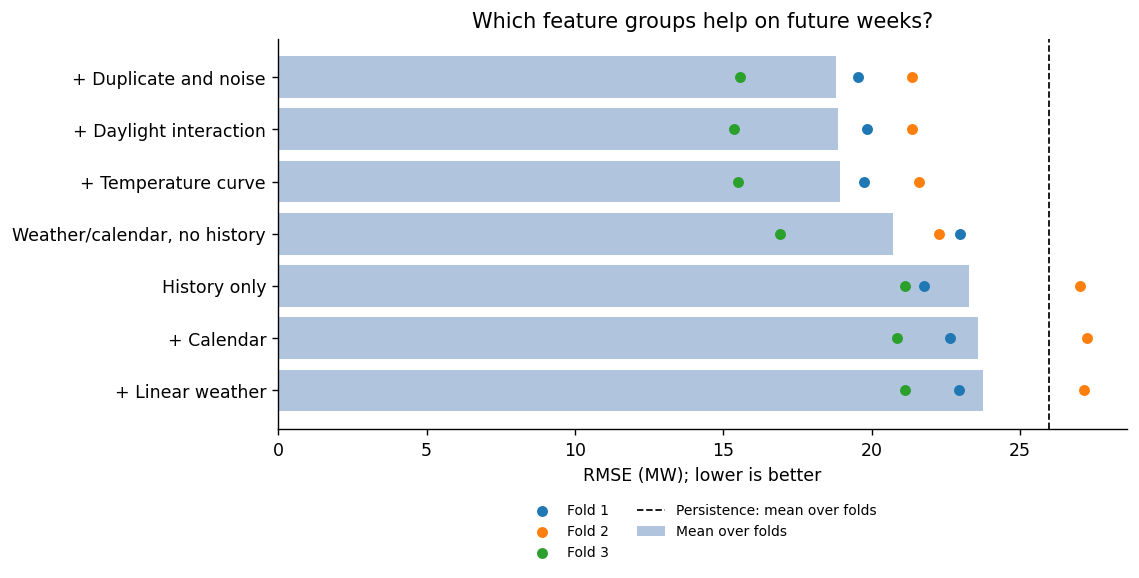

In [23]:
ordered = cv_results.sort_values("mean_rmse", ascending=False)
positions = np.arange(len(ordered))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.barh(positions, ordered["mean_rmse"], color="lightsteelblue", label="Mean over folds")
for i in range(1, 4):
    ax.scatter(ordered[f"fold_{i}"], positions, s=28, label=f"Fold {i}", zorder=3)
ax.axvline(np.mean(persistence_cv), color="black", linestyle="--",
           linewidth=1, label="Persistence: mean over folds")
ax.set_yticks(positions)
ax.set_yticklabels(ordered.index)
ax.set(title="Which feature groups help on future weeks?",
       xlabel="RMSE (MW); lower is better")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, frameon=False)
plt.show()

**Read the individual fold scores as well as the average.** A feature that helps
only in one week may be exploiting a particular regime. The dots show differences
between these weeks, not independent confidence intervals.

If two sets are close, prefer the one you can justify and maintain. A duplicate
temperature sensor can sometimes help because its missing readings occur at
different times. That is a reason to test redundancy rather than apply a blanket
correlation threshold.

## 13. Validate the selected features and inspect importance

Now compare the selected representation using Ridge and a modest random forest.
The forest can learn additional nonlinearities and interactions. It may also
overfit, so judge it on future observations rather than training fit.

Compare both with persistence (`prediction = last observed value`) and the training
mean. Choose the lowest validation RMSE among these four choices. This validation
period is used for selection and diagnostics, so its winning score is not the final
unbiased assessment.

In [24]:
fitted_models = {
    "Ridge": make_ridge(),
    "Random forest": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=160, max_depth=10, min_samples_leaf=6,
            max_features=0.8, random_state=42, n_jobs=1,
        )),
    ]),
}
valid_predictions = {
    "Persistence": valid["gas_lag_1"].to_numpy(),
    "Training mean": np.full(len(valid), y_train.mean()),
}
for name, estimator in fitted_models.items():
    estimator.fit(train[selected_cols], y_train)
    valid_predictions[name] = estimator.predict(valid[selected_cols])

validation_scores = pd.DataFrame({
    name: {
        "MAE": mean_absolute_error(valid["target"], prediction),
        "RMSE": np.sqrt(mean_squared_error(valid["target"], prediction)),
    }
    for name, prediction in valid_predictions.items()
}).T.sort_values("RMSE")
display(validation_scores)
chosen_name = validation_scores["RMSE"].idxmin()
print("Chosen model:", chosen_name)

,MAE,RMSE
Ridge,14.768,20.096
Random forest,16.321,21.641
Persistence,24.090,30.637
Training mean,70.095,87.508


Chosen model: Ridge


### Permutation importance asks how a fitted model uses its inputs

Shuffle one input on the validation set, keeping the model fixed, and measure
how much its prediction score deteriorates. With negative-RMSE scoring, positive
importance is the **increase in RMSE** caused by shuffling.

This describes this model's reliance on a column, not the column's causal effect
or universal usefulness. Correlated substitutes can obscure individual importance.
Ordinary shuffling also breaks time structure. Shuffling raw temperature alone
also breaks its deterministic relationship with the squared-temperature feature.
Treat this as a diagnostic and check proposed removals by refitting on chronological
folds; to test temperature as a group, remove all its representations together.

Error bars below show variation across repeated shuffles, **not** sampling
confidence intervals. If these diagnostics lead you to change features, validation
has become part of that tuning decision. This walkthrough makes no further changes.

[Permutation importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html)

,mean_rmse_increase,shuffle_sd
temp_sq,39.671,0.671
gas_lag_1,28.132,0.636
hour_cos,17.805,0.627
wind_fcst,2.271,0.240
is_weekend,0.894,0.121
gas_change_1,0.474,0.099
hour_sin,0.225,0.051
gas_lag_24,0.113,0.017
cloud_fcst,0.053,0.026
temp_fcst,0.017,0.010


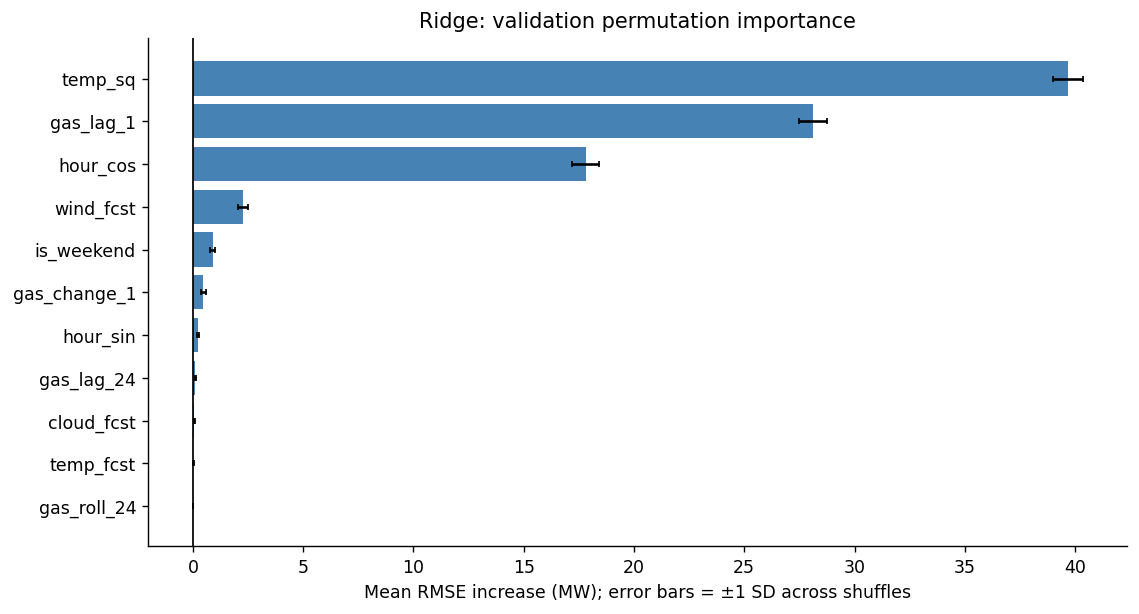

In [25]:
# If a simple baseline wins, inspect Ridge as a separate diagnostic model.
importance_name = chosen_name if chosen_name in fitted_models else "Ridge"
importance_model = fitted_models[importance_name]
importance_result = permutation_importance(
    importance_model, valid[selected_cols], valid["target"],
    scoring="neg_root_mean_squared_error", n_repeats=8, random_state=42, n_jobs=1,
)
importance_table = pd.DataFrame({
    "mean_rmse_increase": importance_result.importances_mean,
    "shuffle_sd": importance_result.importances_std,
}, index=selected_cols).sort_values("mean_rmse_increase")
display(importance_table.iloc[::-1])

fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
ax.barh(importance_table.index, importance_table["mean_rmse_increase"],
        xerr=importance_table["shuffle_sd"], color="steelblue", capsize=2)
ax.axvline(0, color="black", linewidth=1)
ax.set(title=f"{importance_name}: validation permutation importance",
       xlabel="Mean RMSE increase (MW); error bars = ±1 SD across shuffles")
plt.show()

## 14. Present performance as a pattern, not just one number

**Questions:** when does the model fail, and is it systematically too high or too low?

Use the same definition `error = actual − prediction` throughout. The table below
compares weekday and weekend errors, including counts. A low average error can
hide large positive and negative mistakes; MAE/RMSE quantify their magnitude.

For presentation, choose a few plots that support a conclusion. A useful sequence
is a data-quality summary, one pattern that motivated features, the feature-set
comparison, and the actual-versus-predicted result.

In [26]:
validation_review = valid[["target", "temp_fcst", "hour", "is_weekend"]].copy()
validation_review["prediction"] = valid_predictions[chosen_name]
validation_review["error"] = validation_review["target"] - validation_review["prediction"]
validation_review["abs_error"] = validation_review["error"].abs()
slice_scores = validation_review.groupby("is_weekend", observed=True).agg(
    n=("error", "size"),
    mean_error=("error", "mean"),
    mae=("abs_error", "mean"),
    rmse=("error", lambda values: np.sqrt(np.mean(values ** 2))),
).rename(index={0: "Weekday", 1: "Weekend"})
display(slice_scores)

,n,mean_error,mae,rmse
is_weekend,,,,
Weekday,432,-0.359,14.480,19.680
Weekend,142,-0.551,15.643,21.314


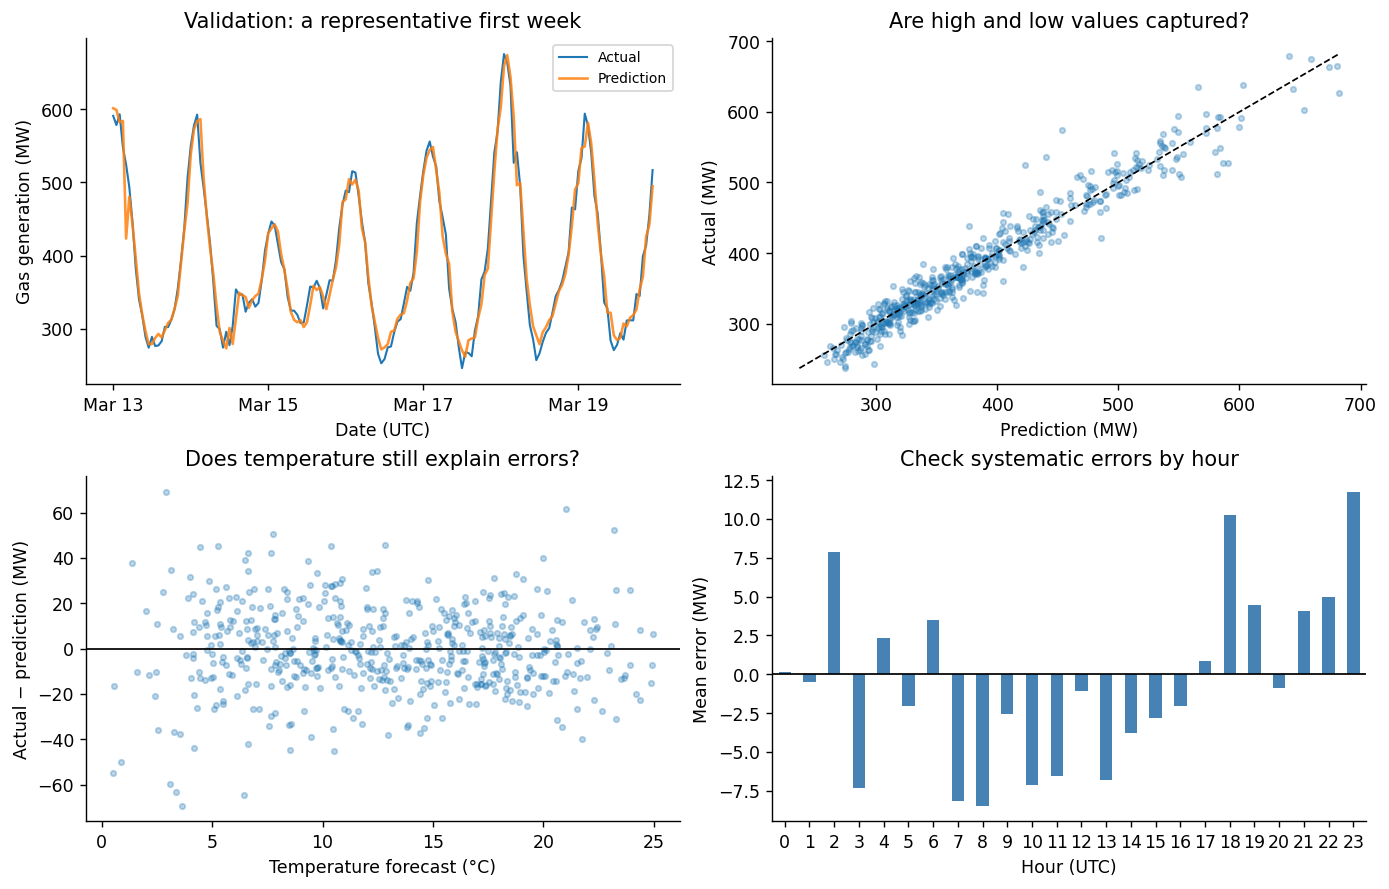

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
first_week = validation_review.loc[
    validation_review.index < validation_review.index.min() + pd.Timedelta(days=7)
]
axes[0, 0].plot(first_week.index, first_week["target"], label="Actual", linewidth=1.2)
axes[0, 0].plot(first_week.index, first_week["prediction"], label="Prediction", alpha=0.85)
axes[0, 0].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[0, 0].set(title="Validation: a representative first week",
               xlabel="Date (UTC)", ylabel="Gas generation (MW)")
axes[0, 0].legend(fontsize=8)

axes[0, 1].scatter(validation_review["prediction"], validation_review["target"],
                   s=10, alpha=0.3)
low = validation_review[["prediction", "target"]].min().min()
high = validation_review[["prediction", "target"]].max().max()
axes[0, 1].plot([low, high], [low, high], "--", color="black", linewidth=1)
axes[0, 1].set(title="Are high and low values captured?",
               xlabel="Prediction (MW)", ylabel="Actual (MW)")

axes[1, 0].scatter(validation_review["temp_fcst"], validation_review["error"],
                   s=10, alpha=0.3)
axes[1, 0].axhline(0, color="black", linewidth=1)
axes[1, 0].set(title="Does temperature still explain errors?",
               xlabel="Temperature forecast (°C)", ylabel="Actual − prediction (MW)")

hour_bias = validation_review.groupby("hour", observed=True)["error"].mean()
hour_bias.plot.bar(ax=axes[1, 1], color="steelblue", rot=0)
axes[1, 1].axhline(0, color="black", linewidth=1)
axes[1, 1].set(title="Check systematic errors by hour",
               xlabel="Hour (UTC)", ylabel="Mean error (MW)")
plt.show()

## 15. Freeze the decision and make one final assessment

The feature set and model type are now fixed. Refit the chosen estimator on
training plus validation; then score the untouched final period once.
Earlier test observations may supply later lag features because the task consists
of successive one-hour forecasts with immediate reporting. The model itself stays
fixed throughout this test block.

Compare the final result with the same persistence baseline. If the result is
disappointing, report it honestly. Revising the model after seeing it would turn
this test period into additional validation.

This synthetic dataset covers only 120 days. Its numerical scores are teaching
results, not a claim about performance on an external dataset or a full year.

In [28]:
frozen_choice = {"model": chosen_name, "feature_set": selected_set,
                 "features": tuple(selected_cols)}
development = pd.concat([train, valid]).sort_index()

if chosen_name == "Persistence":
    final_prediction = test["gas_lag_1"].to_numpy()
elif chosen_name == "Training mean":
    final_prediction = np.full(len(test), development["target"].mean())
else:
    final_model = clone(fitted_models[chosen_name])
    final_model.fit(development[selected_cols], development["target"])
    final_prediction = final_model.predict(test[selected_cols])

final_test_scores = pd.DataFrame({
    "Chosen procedure": {
        "MAE": mean_absolute_error(test["target"], final_prediction),
        "RMSE": np.sqrt(mean_squared_error(test["target"], final_prediction)),
    },
    "Persistence": {
        "MAE": mean_absolute_error(test["target"], test["gas_lag_1"]),
        "RMSE": np.sqrt(mean_squared_error(test["target"], test["gas_lag_1"])),
    },
}).T
display(final_test_scores)

rmse_improvement = 100 * (
    1 - final_test_scores.loc["Chosen procedure", "RMSE"]
        / final_test_scores.loc["Persistence", "RMSE"]
)
print("Frozen model:", frozen_choice["model"])
print("Frozen feature set:", frozen_choice["feature_set"])
print(f"Final RMSE reduction versus persistence: {rmse_improvement:.1f}%")
print("Scope: successive one-hour forecasts, observed previous-hour generation,")
print("       target-hour weather forecasts already available, one held-out period.")

,MAE,RMSE
Chosen procedure,14.086,18.590
Persistence,21.647,28.104


Frozen model: Ridge
Frozen feature set: + Temperature curve
Final RMSE reduction versus persistence: 33.9%
Scope: successive one-hour forecasts, observed previous-hour generation,
       target-hour weather forecasts already available, one held-out period.


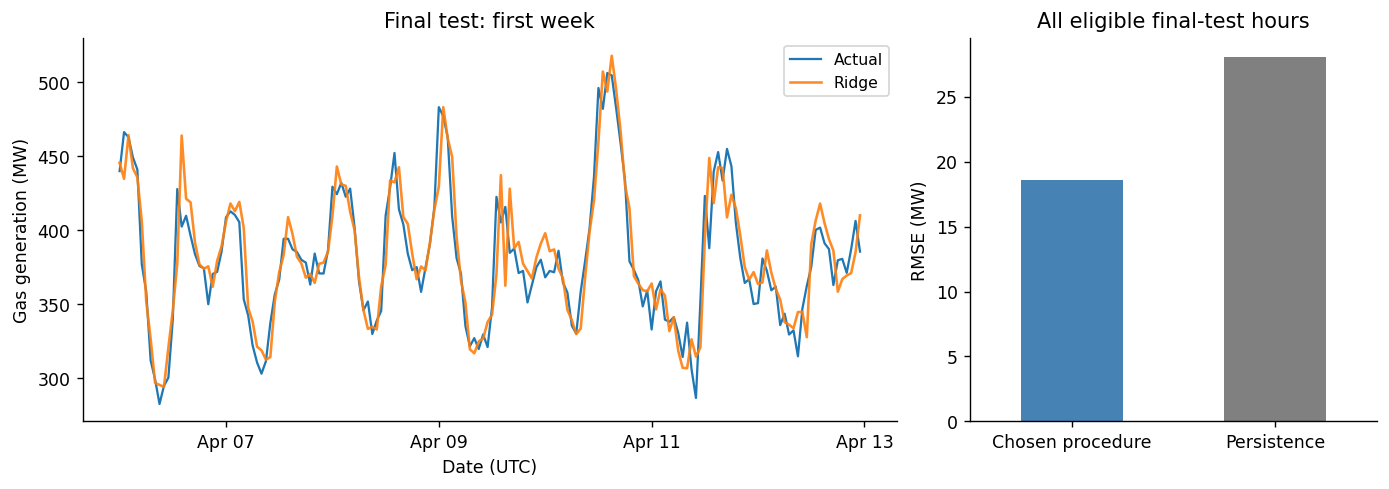

In [29]:
test_result = pd.DataFrame({
    "Actual": test["target"], "Prediction": final_prediction,
}, index=test.index)
shown = test_result.loc[
    test_result.index < test_result.index.min() + pd.Timedelta(days=7)
]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(shown.index, shown["Actual"], label="Actual", linewidth=1.3)
axes[0].plot(shown.index, shown["Prediction"], label=chosen_name, alpha=0.9)
axes[0].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=6))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[0].set(title="Final test: first week", xlabel="Date (UTC)",
            ylabel="Gas generation (MW)")
axes[0].legend(fontsize=9)
final_test_scores["RMSE"].plot.bar(ax=axes[1], color=["steelblue", "gray"], rot=0)
axes[1].set(title="All eligible final-test hours", xlabel="", ylabel="RMSE (MW)")
plt.show()

### A concise presentation template

1. **Task and information:** "I forecast one hour ahead using information available
   when the forecast is issued."
2. **Data checks:** "I checked keys, duplicate records, missing hours, units, and
   forecast availability. Target gaps were excluded consistently from evaluation."
3. **Pattern and experiment:** "A temperature curve suggested a quadratic feature;
   I compared it with simpler feature sets on the same future weeks."
4. **Result and limit:** quote the computed baseline comparison and one clear
   diagnostic, then state that the evaluation covers one time period and the
   specified one-step reporting setup.

You have completed the core tutorial. The next three sections teach additional
APIs on training data only. They do not change the frozen result above.

## 16. Optional: Lasso as embedded feature selection

These three appendices demonstrate additional methods using only the existing training block and its chronological CV folds. They do not revise the frozen model or access validation/test data. To use one in a future analysis, include it in the candidate plan before final assessment.

[Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) adds an absolute-value penalty to squared-error fitting. Increasing `alpha` generally encourages more shrinkage and zero coefficients. It can therefore fit a predictor and select a subset in one procedure. Scaling matters: the penalty otherwise treats coefficients attached to different measurement units unevenly.

Below, each fold fits its own imputer and scaler before fitting Lasso. We try only three prespecified penalties. As in the core comparison, we report the average RMSE across the same future folds. `GridSearchCV` then refits the chosen pipeline on the entire training block; its coefficients and retained names are shown afterward.

A zero coefficient means this fitted, penalized model did not retain that variable. It is not proof that the variable has no association or causal effect. Highly correlated inputs, such as a temperature reading and its near-copy, can substitute for one another, so the selected names may be unstable. These coefficients are not accompanied by ordinary post-selection p-values.

In [30]:
from sklearn.linear_model import Lasso as opt_Lasso
from sklearn.model_selection import GridSearchCV as opt_GridSearchCV

opt_lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", opt_Lasso(max_iter=50000)),
])
opt_lasso_search = opt_GridSearchCV(
    opt_lasso_pipeline, {"model__alpha": [0.1, 1.0, 5.0]},
    cv=cv_splits, scoring="neg_root_mean_squared_error", n_jobs=1,
    refit=True, error_score="raise",
)
opt_lasso_search.fit(X_train, y_train)
opt_lasso_cv = pd.DataFrame({
    "alpha": opt_lasso_search.cv_results_["param_model__alpha"],
    "mean_fold_RMSE": -opt_lasso_search.cv_results_["mean_test_score"],
}).sort_values("mean_fold_RMSE")
display(opt_lasso_cv)

opt_lasso_coefficients = pd.Series(
    opt_lasso_search.best_estimator_.named_steps["model"].coef_,
    index=all_feature_cols, name="coefficient_after_standardization",
)
opt_lasso_order = opt_lasso_coefficients.abs().sort_values(ascending=False).index
display(opt_lasso_coefficients.loc[opt_lasso_order].to_frame())
opt_lasso_selected = opt_lasso_coefficients.index[opt_lasso_coefficients.abs() > 1e-8].tolist()
print("Chosen alpha:", opt_lasso_search.best_params_["model__alpha"])
print("Nonzero fitted coefficients:", opt_lasso_selected)

,alpha,mean_fold_RMSE
1,1.000,18.880
0,0.100,18.898
2,5.000,20.606


,coefficient_after_standardization
temp_sq,35.193
gas_lag_1,25.541
hour_cos,18.832
wind_fcst,-5.331
is_weekend,-3.208
gas_change_1,2.519
hour_sin,-0.600
gas_lag_24,0.422
daylight_clear,-0.163
gas_roll_24,0.000


Chosen alpha: 1.0
Nonzero fitted coefficients: ['gas_lag_1', 'gas_lag_24', 'gas_change_1', 'hour_sin', 'hour_cos', 'is_weekend', 'wind_fcst', 'temp_sq', 'daylight_clear']


## 17. Optional: marginal screening inside the pipeline

[SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html) ranks individual input columns and retains a chosen number. Here `f_regression` scores each feature's marginal linear relationship with the target; a Ridge model then fits the retained columns jointly. This differs from Lasso, whose coefficients are fitted together under a penalty.

Screening uses the target, so selecting columns once using all training rows and then cross-validating the reduced matrix would contaminate the inner validation folds. Putting the selector inside the pipeline makes it relearn the ranking using only each fold's fitting rows. Imputation also stays inside that pipeline. We compare five features, nine features, and all features on the existing chronological folds.

Marginal ranking has limits. A U-shaped effect can have little linear correlation, and correlated substitutes can occupy several top positions. A useful interaction can also be missed when its components look weak separately. Explicitly engineered nonlinear terms can help, but a screening score alone is not a general test of usefulness.

The displayed F scores are ranking statistics here. Serial dependence and the search over subsets prevent interpreting ordinary textbook p-values as valid evidence for the final selected model. We report selected names and CV prediction loss, without post-selection significance claims.

In [31]:
from sklearn.feature_selection import SelectKBest as opt_SelectKBest
from sklearn.feature_selection import f_regression as opt_f_regression
from sklearn.model_selection import GridSearchCV as opt_GridSearchCV

opt_screen_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("screen", opt_SelectKBest(score_func=opt_f_regression)),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])
opt_screen_search = opt_GridSearchCV(
    opt_screen_pipeline, {"screen__k": [5, 9, "all"]},
    cv=cv_splits, scoring="neg_root_mean_squared_error", n_jobs=1,
    refit=True, error_score="raise",
)
opt_screen_search.fit(X_train, y_train)
opt_screen_cv = pd.DataFrame({
    "k": opt_screen_search.cv_results_["param_screen__k"],
    "mean_fold_RMSE": -opt_screen_search.cv_results_["mean_test_score"],
}).sort_values("mean_fold_RMSE")
display(opt_screen_cv)
opt_screen_fitted = opt_screen_search.best_estimator_.named_steps["screen"]
opt_screen_names = np.asarray(all_feature_cols)[opt_screen_fitted.get_support()].tolist()
opt_screen_scores = pd.Series(opt_screen_fitted.scores_, index=all_feature_cols, name="marginal_F_score")
display(opt_screen_scores.sort_values(ascending=False).to_frame())
print("Chosen k:", opt_screen_search.best_params_["screen__k"])
print("Retained features:", opt_screen_names)

,k,mean_fold_RMSE
2,all,18.809
1,9,19.201
0,5,19.748


,marginal_F_score
gas_lag_1,"8,936.452"
temp_sq,"2,688.945"
gas_lag_24,"1,313.558"
gas_change_1,222.937
hour_cos,187.380
daylight_clear,82.869
gas_roll_24,57.878
wind_fcst,36.988
hour_sin,28.460
temp_fcst,15.040


Chosen k: all
Retained features: ['gas_lag_1', 'gas_lag_24', 'gas_roll_24', 'gas_change_1', 'hour_sin', 'hour_cos', 'is_weekend', 'temp_fcst', 'wind_fcst', 'cloud_fcst', 'temp_sq', 'daylight_clear', 'temp_copy', 'noise_1', 'noise_2']


## 18. Optional: numeric and categorical columns together

Day names are categories known from the forecast timestamp. Assigning Monday=0 through Sunday=6 and treating that number as an ordinary linear predictor would impose an arbitrary straight-line effect. One-hot encoding instead gives each observed day its own indicator. It is one possible representation; the earlier cyclic calendar features remain useful alternatives.

[ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) applies different preparation steps to different column groups. Numeric columns receive median imputation and scaling. The day-name column receives categorical imputation and [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html). With `handle_unknown="ignore"`, an unseen category produces zeros for that encoded feature group instead of an error. This is a fallback behavior, not a guarantee of accurate prediction for unseen categories.

We create a separate training copy, preserve its row order, and reuse the same CV positions. Category discovery, imputation, scaling, and regression are all refitted inside each fold. Ridge with `solver="lsqr"` can handle the resulting numeric matrix whether the combined representation is sparse or dense.

These results answer whether a few penalties work with this representation on training CV. They do not demonstrate that day names improve the final model. A planned comparison with the existing calendar representation would be needed before selecting that addition.

In [32]:
from sklearn.compose import ColumnTransformer as opt_ColumnTransformer
from sklearn.preprocessing import OneHotEncoder as opt_OneHotEncoder
from sklearn.model_selection import GridSearchCV as opt_GridSearchCV

opt_category_train = X_train.copy()
opt_category_train["day_name"] = train.index.day_name()
opt_numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
opt_category_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", opt_OneHotEncoder(handle_unknown="ignore")),
])
opt_preparation = opt_ColumnTransformer([
    ("numeric", opt_numeric_steps, all_feature_cols),
    ("calendar", opt_category_steps, ["day_name"]),
])
opt_category_pipeline = Pipeline([
    ("preparation", opt_preparation),
    ("model", Ridge(solver="lsqr")),
])
opt_category_search = opt_GridSearchCV(
    opt_category_pipeline, {"model__alpha": [0.1, 1.0, 5.0]},
    cv=cv_splits, scoring="neg_root_mean_squared_error", n_jobs=1,
    refit=True, error_score="raise",
)
opt_category_search.fit(opt_category_train, y_train)
opt_category_cv = pd.DataFrame({
    "alpha": opt_category_search.cv_results_["param_model__alpha"],
    "mean_fold_RMSE": -opt_category_search.cv_results_["mean_test_score"],
}).sort_values("mean_fold_RMSE")
display(opt_category_cv)
opt_fitted_preparation = opt_category_search.best_estimator_.named_steps["preparation"]
opt_fitted_encoder = opt_fitted_preparation.named_transformers_["calendar"].named_steps["encoder"]
print("Days learned from the training block:", opt_fitted_encoder.categories_[0].tolist())
print("Chosen alpha:", opt_category_search.best_params_["model__alpha"])

,alpha,mean_fold_RMSE
2,5.000,18.894
1,1.000,18.965
0,0.100,18.987


Days learned from the training block: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
Chosen alpha: 5.0


## 19. A compact reference for your own analysis

### Data operations

| Goal | Common pattern | Meaning or caution |
|---|---|---|
| Load a CSV | `pd.read_csv("data.csv", parse_dates=["timestamp"])` | Then verify numeric types and the timezone |
| Inspect | `df.head(); df.info(); df.describe()` | Check units, types, ranges, and what a row represents |
| Select rows/columns | `df.loc[mask, ["a", "b"]]` | Parenthesize conditions joined with `&` or `\|` |
| Change selected values | `df.loc[mask, "a"] = value` | Avoid chained assignment such as `df[mask]["a"] = ...` |
| Parse time | `pd.to_datetime(df["time"], utc=True, errors="coerce")` | Inspect failed parses; know the original timezone |
| Parse numbers | `pd.to_numeric(df["x"], errors="coerce")` | Count newly missing values |
| Check keys | `df.duplicated(["time", "entity"], keep=False)` | Resolve meaning before aggregation |
| Summarize groups | `df.groupby("g").agg(mean_x=("x", "mean"), n=("x", "count"))` | `count` excludes missing values; `size` counts rows |
| Align a group statistic | `df.groupby("g")["x"].transform("mean")` | Same row index; target-derived features need training-only fitting |
| Reshape | `pivot`, `pivot_table`, `melt` | Choose between rearranging and intentional aggregation |
| Join | `left.merge(right, on="key", validate="many_to_one")` | State expected key cardinality explicitly |
| Regularize time | `series.asfreq("h")` | Missing timestamps become missing values |
| Aggregate time | `series.resample("D").mean()` | Inspect coverage and when the aggregate becomes available |
| Construct past history | `series.shift(1).rolling(24).mean()` | Sort/regularize first; group by entity if needed |
| Inspect lag dependence | `series.autocorr(lag=24)` | Use the regular time grid; association alone does not select a useful lag |
| Difference | `series.shift(1).diff()` | Previous observed change, available for the next forecast |
| Relative change | `series.shift(1).pct_change(fill_method=None)` | Explicitly handle zeros and missing observations |
| Missingness flag | `df["x"].isna().astype(int)` | Can be predictive if absence itself has meaning |
| Positive skew | `np.log1p(df["x"])` | Appropriate domain matters; a transformed target changes loss interpretation |
| Replace a category | `df["kind"].map({"A": 0, "B": 1})` | Unmapped values become missing; avoid arbitrary numeric ordering for nominal categories |

For genuine local timestamps, `utc=True` is correct only if the input has a timezone
offset or naive timestamps really denote UTC. Otherwise localize to the source
timezone first, resolving daylight-saving ambiguity, then convert to UTC.

### Outliers: a transform requires a reason

First check whether an extreme value is a unit error, duplicate, broken sensor, or
a real event. If you decide to clip predictors, learn thresholds from training data:

```python
low, high = train["wind_fcst"].quantile([0.01, 0.99])
train_clipped = train["wind_fcst"].clip(low, high)
valid_clipped = valid["wind_fcst"].clip(low, high)
```

Within CV, those quantiles must be learned separately inside each fold. The core
models above do not use clipping. Do not remove difficult validation/test targets
merely because they increase error.

### Which plot answers which question?

| Question | Plot |
|---|---|
| How does this change over time? | `ax.plot(time, value)` |
| What is the distribution? | `series.hist(ax=ax, bins=...)` |
| How do groups compare? | `group_means.plot.bar(ax=ax)` or a box plot |
| What shape connects two variables? | `ax.scatter(x, y, alpha=...)` plus a binned mean |
| What happens across two categories? | `pivot_table` followed by `ax.imshow(...)` |
| What does my current model still miss? | Residuals against time, features, fitted values, or groups |
| Which candidate generalizes better? | Same-window error table and fold comparison plot |

Always label units, identify the period used, and state what one observation
represents. Use one or two sentences to explain the decision a figure supports.
To export a figure, call `fig.savefig("my_figure.png", dpi=160, bbox_inches="tight")`
before `plt.show()`.

### Which feature-selection tool should you reach for?

| Approach | Good first use | Main limitation |
|---|---|---|
| Availability/quality audit | Remove unusable measurements, constants, and genuine duplicates | A high correlation cannot make a late measurement usable |
| Pearson/Spearman or univariate scores | Narrow a large list for further inspection | Marginal screening misses interactions and nonmonotone relationships |
| Small feature-group comparisons | Test a specific mechanism on future periods | Many adaptive comparisons can overfit validation |
| Ridge | Stabilize a model with many related inputs | Usually shrinks coefficients without setting them exactly to zero |
| Lasso | Get a sparse candidate linear representation | Correlated alternatives can be selected unstably |
| Permutation importance | Inspect a model after verifying predictive performance | Correlated substitutes and temporal shuffling complicate interpretation |
| Forests | Explore nonlinear responses and interactions | Importance is model-dependent; future validation is still necessary |

With hundreds of features, first use metadata and quality checks, then a small
screening table and a regularized baseline. Inspect a few plausible relationships,
compare meaningful groups, and check stability across periods. Start with these
steps before expensive recursive or exhaustive subset searches.

### Do you need hypothesis tests?

Not for every plot or feature decision. This workflow is primarily predictive:
the main evidence is improvement on future observations under the same evaluation
scheme. A small training p-value is not evidence of useful incremental prediction.

Formal tests become relevant when the question is specifically inferential—for
example, estimating a group effect or testing a prespecified contrast. Serial
dependence, repeated feature searches, and model misspecification affect those tests.
Ordinary independent-error OLS p-values and confidence intervals are not automatically
valid for this hourly dataset. The Lasso choices, correlation rankings, and permutation
error bars above are not hypothesis tests.

## 20. Short practice exercises and answers

Try each exercise before opening the answer. Work with training data; keep the
final test reserved if you create a new modeling experiment.

### Exercise 1: a new binned plot

Replace temperature with `wind_fcst` in section 8. Plot the mean target and the
number of observations per bin. What plausible mechanism does the curve suggest?

<details>
<summary>Answer and minimal pattern</summary>

```python
wind_view = train[["wind_fcst", "target"]].dropna().copy()
wind_view["bin"] = pd.qcut(wind_view["wind_fcst"], q=8, duplicates="drop")
wind_curve = wind_view.groupby("bin", observed=True).agg(
    wind=("wind_fcst", "mean"),
    target=("target", "mean"),
    n=("target", "size"),
)
fig, ax = plt.subplots()
ax.plot(wind_curve["wind"], wind_curve["target"], "o-")
ax.set(xlabel="Wind forecast (m/s)", ylabel="Mean gas generation (MW)")
plt.show()
```

Greater wind availability can coincide with less gas generation in this toy system.
The marginal curve alone does not isolate that mechanism from calendar or temperature
effects. Test whether the forecast improves the current model.
</details>

### Exercise 2: spot the leak

Why is `data["gas"].rolling(24).mean()` invalid for this task? What about
`data["gas"].shift(-1)`?

<details>
<summary>Answer</summary>

The first includes the target-hour generation itself; the second uses next hour's
generation. Use `data["gas"].shift(1).rolling(24).mean()` for a trailing feature
available at this forecast origin. A centered rolling mean is also inappropriate
because it includes later observations.
</details>

### Exercise 3: test a feature group

Before looking at scores, predict the effect of removing `temp_sq` from a model
that already includes linear weather. Compare both on `cv_splits` using the same
eligible rows.

<details>
<summary>Answer</summary>

Use the two corresponding entries in `candidate_sets` and `cross_val_score` exactly
as in section 12. Refitting is essential. Keeping the original coefficients and
zeroing a column asks a different question. The expected gain is motivated by the
U-shaped plot, but the size and consistency must be read from the folds.
</details>

### Exercise 4: explain a result in 30 seconds

Choose one figure and explain (i) its question, (ii) its main pattern, (iii) the
feature experiment it suggests, and (iv) one limitation.

<details>
<summary>Example answer</summary>

"The binned temperature plot asks whether a straight-line effect is adequate.
Generation is higher at both low and high temperatures, so I tested a quadratic
temperature term. I compared it with the linear-weather model on the same future
weeks. The plot is a marginal association; other variables may contribute, so
validation rather than the plot alone determines whether I keep the term."
</details>

### Main documentation

- [pandas reshaping](https://pandas.pydata.org/docs/user_guide/reshaping.html),
  [groupby](https://pandas.pydata.org/docs/user_guide/groupby.html),
  [time series](https://pandas.pydata.org/docs/user_guide/timeseries.html).
- [Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html).
- [scikit-learn pipelines and pitfalls](https://scikit-learn.org/stable/common_pitfalls.html),
  [feature selection](https://scikit-learn.org/stable/modules/feature_selection.html),
  [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

The notebook uses ordinary pandas, NumPy, Matplotlib, and scikit-learn APIs.
Package versions from the execution check are recorded in notebook metadata.